In [37]:
import pandas as pd
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder

In [3]:
df = pd.read_csv("../data/demand_forecasting_engineered.csv")

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Promotion_Discount,Low_Inventory,Previous_Price,Price_Change,Price_Change_Pct,Previous_Demand,Previous_7Day_Avg_Demand,Demand_Trend,Inventory_Coverage_Days,Weekend_Promotion
0,2022-01-08,S001,P0001,Electronics,North,308,96,248,68.56,10,...,10,0,66.07,2.49,3.768730,87.0,105.857143,-18.857143,2.909582,1
1,2022-01-09,S001,P0001,Electronics,North,212,57,0,62.76,10,...,0,1,68.56,-5.80,-8.459743,113.0,105.571429,7.428571,2.008119,0
2,2022-01-10,S001,P0001,Electronics,North,403,88,0,68.99,5,...,0,0,62.76,6.23,9.926705,87.0,106.000000,-19.000000,3.801887,0
3,2022-01-11,S001,P0001,Electronics,North,315,112,0,73.71,0,...,0,0,68.99,4.72,6.841571,99.0,101.285714,-2.285714,3.110014,0
4,2022-01-12,S001,P0001,Electronics,North,203,70,179,65.76,10,...,0,1,73.71,-7.95,-10.785511,103.0,106.428571,-3.428571,1.907383,0


In [4]:
df['Date'] = pd.to_datetime(df['Date'])

df = df.sort_values('Date').reset_index(drop=True)

In [5]:
df[['Date', 'Demand']].head()

,Date,Demand
0,2022-01-08,113
1,2022-01-08,143
2,2022-01-08,110
3,2022-01-08,83
4,2022-01-08,152


In [6]:
print(df['Date'].min())
print(df['Date'].max())

2022-01-08 00:00:00
2024-01-30 00:00:00


In [7]:
df['Year'].value_counts().sort_index()

Year
2022    35800
2023    36500
2024     3000
Name: count, dtype: int64

In [8]:
df.groupby('Year')['Date'].agg(['min', 'max', 'count'])

,min,max,count
Year,,,
2022,2022-01-08,2022-12-31,35800
2023,2023-01-01,2023-12-31,36500
2024,2024-01-01,2024-01-30,3000


In [10]:
train = df[df['Date'] < '2023-08-01'].copy()
test = df[df['Date'] >= '2023-08-01'].copy()

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (57000, 34)
Test shape: (18300, 34)


In [11]:
print("Train period:")
print(train['Date'].min(), "→", train['Date'].max())

print("\nTest period:")
print(test['Date'].min(), "→", test['Date'].max())

Train period:
2022-01-08 00:00:00 → 2023-07-31 00:00:00

Test period:
2023-08-01 00:00:00 → 2024-01-30 00:00:00


In [12]:
features = [
    'Price',
    'Discount',
    'Promotion',
    'Competitor Pricing',
    'Price_Difference',
    'Price_Ratio',
    'Effective_Price',
    'Promotion_Discount',
    'Price_Change',
    'Price_Change_Pct',
    'Previous_Demand',
    'Previous_7Day_Avg_Demand',
    'Demand_Trend',
    'Inventory Level',
    'Inventory_Coverage_Days',
    'Category',
    'Region',
    'Weather Condition',
    'Seasonality',
    'Epidemic',
    'Year',
    'Month',
    'Day',
    'DayOfWeek',
    'IsWeekend',
    'Weekend_Promotion',
    'Low_Inventory',
    'Store ID',
    'Product ID'
]

In [13]:
X_train = train[features]
y_train = train['Demand']

X_test = test[features]
y_test = test['Demand']

In [14]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (57000, 29)
y_train: (57000,)
X_test: (18300, 29)
y_test: (18300,)


In [16]:
baseline = DummyRegressor(strategy='mean')

baseline.fit(X_train[['Previous_Demand']], y_train)

baseline_pred = baseline.predict(X_test[['Previous_Demand']])

In [17]:
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE :", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R²  :", baseline_r2)

Baseline MAE : 36.083606365640875
Baseline RMSE: 45.86127086422785
Baseline R²  : -0.0003087929837850556


In [21]:
categorical_features = [
    'Category',
    'Region',
    'Weather Condition',
    'Seasonality',
    'Store ID',
    'Product ID'
]

numerical_features = [
    col for col in features
    if col not in categorical_features
]

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['Category', 'Region', 'Weather Condition', 'Seasonality', 'Store ID', 'Product ID']
Numerical: ['Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Price_Difference', 'Price_Ratio', 'Effective_Price', 'Promotion_Discount', 'Price_Change', 'Price_Change_Pct', 'Previous_Demand', 'Previous_7Day_Avg_Demand', 'Demand_Trend', 'Inventory Level', 'Inventory_Coverage_Days', 'Epidemic', 'Year', 'Month', 'Day', 'DayOfWeek', 'IsWeekend', 'Weekend_Promotion', 'Low_Inventory']


In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            'passthrough',
            numerical_features
        )
    ]
)

In [23]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [24]:
rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', rf_model)
    ]
)

In [25]:
print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Categorical: ['Category', 'Region', 'Weather Condition', 'Seasonality', 'Store ID', 'Product ID']
Numerical: ['Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Price_Difference', 'Price_Ratio', 'Effective_Price', 'Promotion_Discount', 'Price_Change', 'Price_Change_Pct', 'Previous_Demand', 'Previous_7Day_Avg_Demand', 'Demand_Trend', 'Inventory Level', 'Inventory_Coverage_Days', 'Epidemic', 'Year', 'Month', 'Day', 'DayOfWeek', 'IsWeekend', 'Weekend_Promotion', 'Low_Inventory']
Number of numerical features: 23
Number of categorical features: 6


In [26]:
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Category', 'Region',
                                                   'Weather Condition',
                                                   'Seasonality', 'Store ID',
                                                   'Product ID']),
                                                 ('numerical', 'passthrough',
                                                  ['Price', 'Discount',
                                                   'Promotion',
                                                   'Competitor Pricing',
                                                   'Price_Difference',
                                                   'Price_Ratio',
                                                   'Effective_Price',
                                                   'Promotion_Discount',
                                                   'Price_Change',
                                                   'Price_Change_Pct',
                                                   'Previous_Demand',
                                                   'Previous_7Day_Avg_Demand',
                                                   'Demand_Trend',
                                                   'Inventory Level',
                                                   'Inventory_Coverage_Days',
                                                   'Epidemic', 'Year', 'Month',
                                                   'Day', 'DayOfWeek',
                                                   'IsWeekend',
                                                   'Weekend_Promotion',
                                                   'Low_Inventory'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [27]:
rf_pred = rf_pipeline.predict(X_test)

In [28]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE :", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²  :", rf_r2)

Random Forest MAE : 17.055481420765023
Random Forest RMSE: 22.09778373929215
Random Forest R²  : 0.7677587535055312


In [30]:
perm_importance = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

In [31]:
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_importance.importances_mean
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

importance_df

,Feature,Importance
9,Price_Change_Pct,22.521216
10,Previous_Demand,11.763642
11,Previous_7Day_Avg_Demand,3.392383
7,Promotion_Discount,2.772162
1,Discount,1.872309
2,Promotion,1.683649
19,Epidemic,1.167648
15,Category,1.008498
4,Price_Difference,0.225148
17,Weather Condition,0.192581


In [32]:
importance_df.head(15)

,Feature,Importance
9,Price_Change_Pct,22.521216
10,Previous_Demand,11.763642
11,Previous_7Day_Avg_Demand,3.392383
7,Promotion_Discount,2.772162
1,Discount,1.872309
2,Promotion,1.683649
19,Epidemic,1.167648
15,Category,1.008498
4,Price_Difference,0.225148
17,Weather Condition,0.192581


In [33]:
importance_df.iloc[15:]

,Feature,Importance
12,Demand_Trend,0.042545
22,Day,0.040791
6,Effective_Price,0.023938
28,Product ID,0.021343
27,Store ID,0.006896
23,DayOfWeek,0.003957
20,Year,0.000000
25,Weekend_Promotion,-0.000293
26,Low_Inventory,-0.000345
16,Region,-0.000357


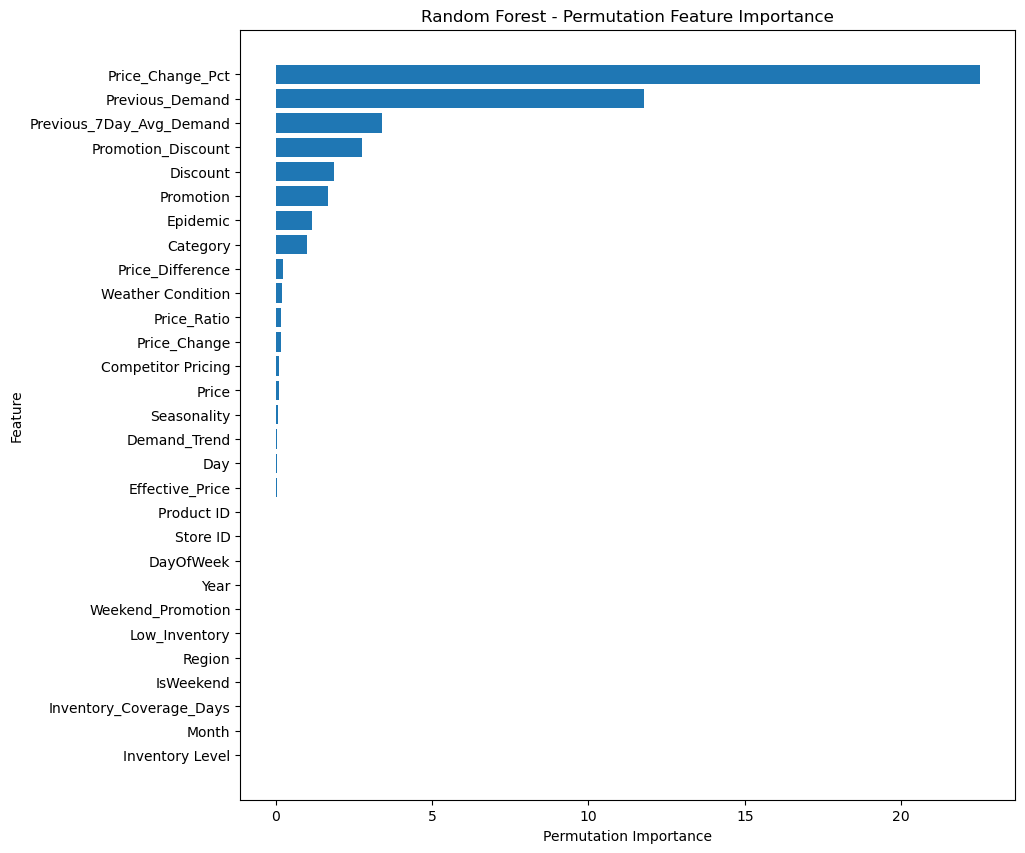

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Permutation Importance')
plt.ylabel('Feature')
plt.title('Random Forest - Permutation Feature Importance')

plt.gca().invert_yaxis()

plt.show()

In [36]:
importance_df.to_csv(
    "../data/random_forest_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [38]:
hgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ),
            categorical_features
        ),
        (
            'numerical',
            'passthrough',
            numerical_features
        )
    ]
)

In [39]:
hgb_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

In [40]:
hgb_pipeline = Pipeline(
    steps=[
        ('preprocessor', hgb_preprocessor),
        ('model', hgb_model)
    ]
)

In [41]:
hgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['Category', 'Region',
                                                   'Weather Condition',
                                                   'Seasonality', 'Store ID',
                                                   'Product ID']),
                                                 ('numerical', 'passthrough',
                                                  ['Price', 'Discount',
                                                   'Promotion',
                                                   'Competitor Pricing',
                                                   'Price_Difference',
                                                   'Price_Ratio',
                                                   'Effective_Price',
                                                   'Promotion_Discount',
                                                   'Price_Change',
                                                   'Price_Change_Pct',
                                                   'Previous_Demand',
                                                   'Previous_7Day_Avg_Demand',
                                                   'Demand_Trend',
                                                   'Inventory Level',
                                                   'Inventory_Coverage_Days',
                                                   'Epidemic', 'Year', 'Month',
                                                   'Day', 'DayOfWeek',
                                                   'IsWeekend',
                                                   'Weekend_Promotion',
                                                   'Low_Inventory'])])),
                ('model',
                 HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300,
                                               random_state=42))])

In [42]:
hgb_pred = hgb_pipeline.predict(X_test)

In [43]:
hgb_mae = mean_absolute_error(y_test, hgb_pred)
hgb_rmse = np.sqrt(mean_squared_error(y_test, hgb_pred))
hgb_r2 = r2_score(y_test, hgb_pred)

print("HistGradientBoosting MAE :", hgb_mae)
print("HistGradientBoosting RMSE:", hgb_rmse)
print("HistGradientBoosting R²  :", hgb_r2)

HistGradientBoosting MAE : 14.766602673278607
HistGradientBoosting RMSE: 19.109324418275094
HistGradientBoosting R²  : 0.8263268894500118


In [44]:
results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Random Forest',
        'HistGradientBoosting'
    ],
    'MAE': [
        baseline_mae,
        rf_mae,
        hgb_mae
    ],
    'RMSE': [
        baseline_rmse,
        rf_rmse,
        hgb_rmse
    ],
    'R2': [
        baseline_r2,
        rf_r2,
        hgb_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Baseline,36.083606,45.861271,-0.000309
1,Random Forest,17.055481,22.097784,0.767759
2,HistGradientBoosting,14.766603,19.109324,0.826327


In [45]:
results.sort_values('R2', ascending=False)

,Model,MAE,RMSE,R2
2,HistGradientBoosting,14.766603,19.109324,0.826327
1,Random Forest,17.055481,22.097784,0.767759
0,Baseline,36.083606,45.861271,-0.000309


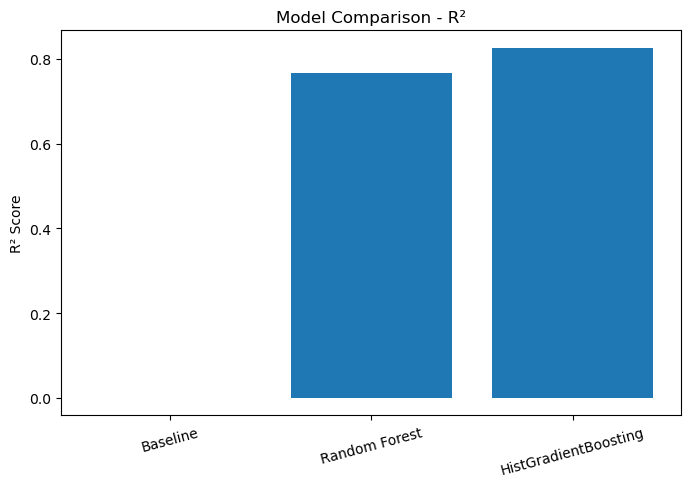

In [46]:
plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['R2']
)

plt.ylabel('R² Score')
plt.title('Model Comparison - R²')

plt.xticks(rotation=15)

plt.show()

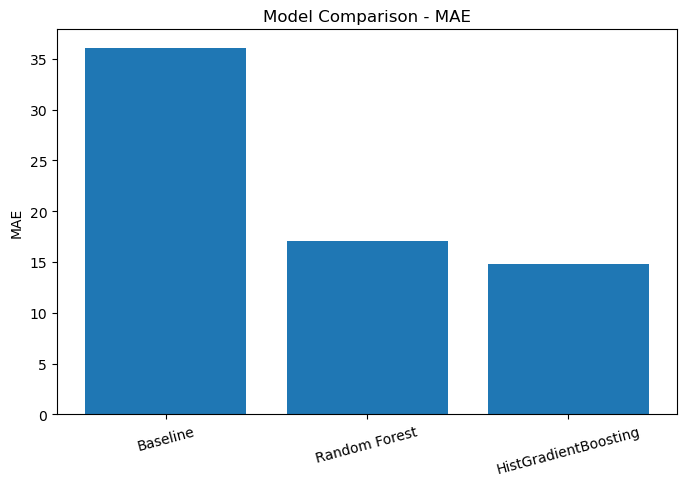

In [47]:
plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['MAE']
)

plt.ylabel('MAE')
plt.title('Model Comparison - MAE')

plt.xticks(rotation=15)

plt.show()

In [48]:
train_model = train[train['Date'] < '2023-05-01'].copy()
validation = train[train['Date'] >= '2023-05-01'].copy()

In [50]:
X_train_model = train_model[features]
y_train_model = train_model['Demand']

X_val = validation[features]
y_val = validation['Demand']

print("Training:", X_train_model.shape)
print("Validation:", X_val.shape)

Training: (47800, 29)
Validation: (9200, 29)


In [51]:
params = [
    {
        'max_iter': 200,
        'learning_rate': 0.05,
        'max_leaf_nodes': 31,
        'min_samples_leaf': 20
    },
    {
        'max_iter': 300,
        'learning_rate': 0.05,
        'max_leaf_nodes': 31,
        'min_samples_leaf': 20
    },
    {
        'max_iter': 300,
        'learning_rate': 0.03,
        'max_leaf_nodes': 31,
        'min_samples_leaf': 20
    },
    {
        'max_iter': 300,
        'learning_rate': 0.05,
        'max_leaf_nodes': 63,
        'min_samples_leaf': 20
    },
    {
        'max_iter': 300,
        'learning_rate': 0.05,
        'max_leaf_nodes': 31,
        'min_samples_leaf': 50
    }
]

In [52]:
tuning_results = []

for i, param in enumerate(params):

    model = HistGradientBoostingRegressor(
        **param,
        random_state=42
    )

    pipeline = Pipeline(
        steps=[
            ('preprocessor', hgb_preprocessor),
            ('model', model)
        ]
    )

    pipeline.fit(X_train_model, y_train_model)

    val_pred = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, val_pred)
    rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    r2 = r2_score(y_val, val_pred)

    tuning_results.append({
        'Experiment': i + 1,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        **param
    })

In [53]:
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df.sort_values(
    'R2',
    ascending=False
)

,Experiment,MAE,RMSE,R2,max_iter,learning_rate,max_leaf_nodes,min_samples_leaf
3,4,14.452320,18.980927,0.858435,300,0.05,63,20
1,2,15.444705,20.110349,0.841087,300,0.05,31,20
4,5,15.421725,20.121708,0.840907,300,0.05,31,50
0,1,16.173371,20.948544,0.827564,200,0.05,31,20
2,3,16.368883,21.199312,0.823411,300,0.03,31,20


In [54]:
best_params = {
    'max_iter': 300,
    'learning_rate': 0.05,
    'max_leaf_nodes': 63,
    'min_samples_leaf': 20
}

In [55]:
champion_model = HistGradientBoostingRegressor(
    **best_params,
    random_state=42
)

In [56]:
champion_pipeline = Pipeline(
    steps=[
        ('preprocessor', hgb_preprocessor),
        ('model', champion_model)
    ]
)

In [57]:
champion_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['Category', 'Region',
                                                   'Weather Condition',
                                                   'Seasonality', 'Store ID',
                                                   'Product ID']),
                                                 ('numerical', 'passthrough',
                                                  ['Price', 'Discount',
                                                   'Promotion',
                                                   'Competitor Pricing',
                                                   'Price_Difference',
                                                   'Price_Ratio',
                                                   'Effective_Pr...
                                                   'Promotion_Discount',
                                                   'Price_Change',
                                                   'Price_Change_Pct',
                                                   'Previous_Demand',
                                                   'Previous_7Day_Avg_Demand',
                                                   'Demand_Trend',
                                                   'Inventory Level',
                                                   'Inventory_Coverage_Days',
                                                   'Epidemic', 'Year', 'Month',
                                                   'Day', 'DayOfWeek',
                                                   'IsWeekend',
                                                   'Weekend_Promotion',
                                                   'Low_Inventory'])])),
                ('model',
                 HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300,
                                               max_leaf_nodes=63,
                                               random_state=42))])

In [58]:
champion_pred = champion_pipeline.predict(X_test)

In [59]:
champion_mae = mean_absolute_error(
    y_test,
    champion_pred
)

champion_rmse = np.sqrt(
    mean_squared_error(y_test, champion_pred)
)

champion_r2 = r2_score(
    y_test,
    champion_pred
)

print("Champion Model MAE :", champion_mae)
print("Champion Model RMSE:", champion_rmse)
print("Champion Model R²  :", champion_r2)

Champion Model MAE : 13.750114040374461
Champion Model RMSE: 17.939930584536132
Champion Model R²  : 0.8469323437778831


In [60]:
prediction_df = pd.DataFrame({
    'Date': test['Date'].values,
    'Actual_Demand': y_test.values,
    'Predicted_Demand': champion_pred
})

prediction_df.head(20)

,Date,Actual_Demand,Predicted_Demand
0,2023-08-01,119,114.133433
1,2023-08-01,27,55.351166
2,2023-08-01,110,100.502668
3,2023-08-01,55,50.272050
4,2023-08-01,153,162.703023
5,2023-08-01,101,99.263732
6,2023-08-01,58,78.494907
7,2023-08-01,124,106.323102
8,2023-08-01,274,246.604338
9,2023-08-01,87,82.402870


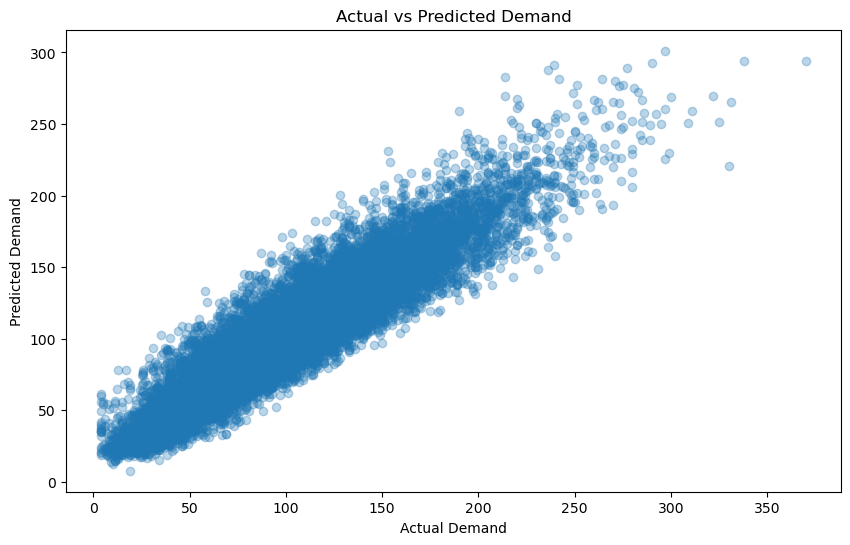

In [61]:
plt.figure(figsize=(10, 6))

plt.scatter(
    prediction_df['Actual_Demand'],
    prediction_df['Predicted_Demand'],
    alpha=0.3
)

plt.xlabel('Actual Demand')
plt.ylabel('Predicted Demand')
plt.title('Actual vs Predicted Demand')

plt.show()

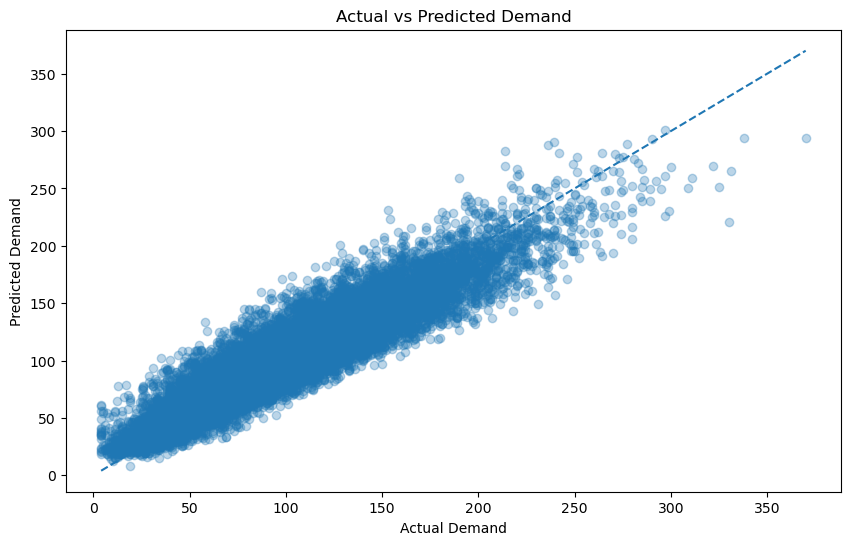

In [66]:
min_value = min(
    prediction_df['Actual_Demand'].min(),
    prediction_df['Predicted_Demand'].min()
)

max_value = max(
    prediction_df['Actual_Demand'].max(),
    prediction_df['Predicted_Demand'].max()
)

plt.figure(figsize=(10, 6))

plt.scatter(
    prediction_df['Actual_Demand'],
    prediction_df['Predicted_Demand'],
    alpha=0.3
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Demand')
plt.ylabel('Predicted Demand')
plt.title('Actual vs Predicted Demand')

plt.show()

In [62]:
prediction_df['Error'] = (
    prediction_df['Actual_Demand']
    - prediction_df['Predicted_Demand']
)

In [63]:
prediction_df['Absolute_Error'] = (
    prediction_df['Error'].abs()
)

In [64]:
prediction_df.describe()

,Date,Actual_Demand,Predicted_Demand,Error,Absolute_Error
count,18300,18300.000000,18300.000000,18300.000000,18300.000000
mean,2023-10-31 00:00:00,103.642350,104.019989,-0.377639,13.750114
min,2023-08-01 00:00:00,4.000000,7.714651,-78.431152,0.000303
25%,2023-09-15 00:00:00,72.000000,75.354799,-11.139527,5.054185
50%,2023-10-31 00:00:00,100.000000,100.697165,0.168851,10.948858
75%,2023-12-16 00:00:00,131.000000,129.140618,10.793106,19.390193
max,2024-01-30 00:00:00,370.000000,301.177664,109.604276,109.604276
std,NaN,45.855445,41.528286,17.936446,11.523139


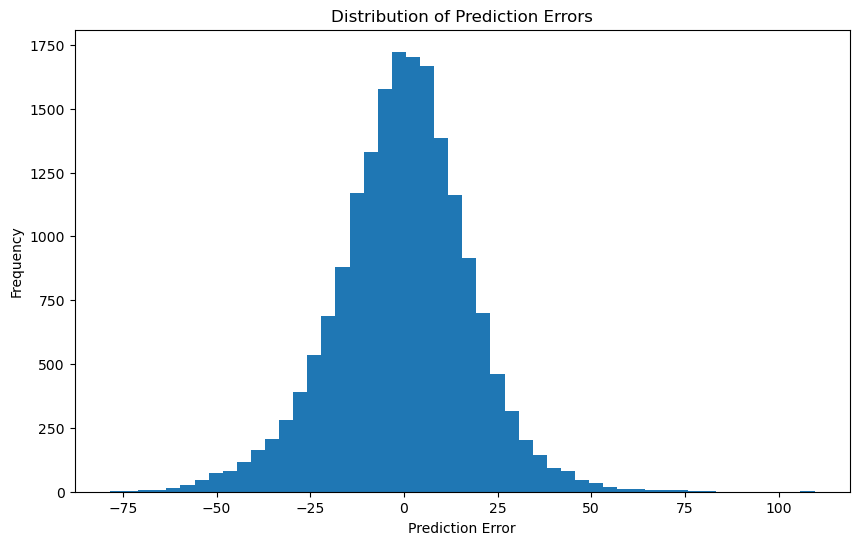

In [65]:
plt.figure(figsize=(10, 6))

plt.hist(
    prediction_df['Error'],
    bins=50
)

plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.title('Distribution of Prediction Errors')

plt.show()

In [67]:
prediction_df['Demand_Band'] = pd.cut(
    prediction_df['Actual_Demand'],
    bins=[0, 50, 100, 150, 200, 300, np.inf],
    labels=[
        '0-50',
        '51-100',
        '101-150',
        '151-200',
        '201-300',
        '300+'
    ]
)

In [68]:
error_by_band = prediction_df.groupby(
    'Demand_Band',
    observed=True
).agg(
    MAE=('Absolute_Error', 'mean'),
    Mean_Error=('Error', 'mean'),
    Count=('Error', 'count')
)

error_by_band

,MAE,Mean_Error,Count
Demand_Band,,,
0-50,13.470034,-10.776345,2095
51-100,11.900575,-4.567178,7194
101-150,13.281042,2.028253,6312
151-200,18.057771,10.860611,2135
201-300,26.761854,21.583503,556
300+,66.470649,66.470649,8


In [69]:
final_results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Random Forest',
        'HistGradientBoosting',
        'Tuned HistGradientBoosting'
    ],
    'MAE': [
        baseline_mae,
        rf_mae,
        hgb_mae,
        champion_mae
    ],
    'RMSE': [
        baseline_rmse,
        rf_rmse,
        hgb_rmse,
        champion_rmse
    ],
    'R2': [
        baseline_r2,
        rf_r2,
        hgb_r2,
        champion_r2
    ]
})

final_results.sort_values('R2', ascending=False)

,Model,MAE,RMSE,R2
3,Tuned HistGradientBoosting,13.750114,17.939931,0.846932
2,HistGradientBoosting,14.766603,19.109324,0.826327
1,Random Forest,17.055481,22.097784,0.767759
0,Baseline,36.083606,45.861271,-0.000309


In [72]:
import joblib



In [77]:
import os

os.makedirs("../Models", exist_ok=True)

In [78]:
joblib.dump(
    champion_pipeline,
    "../Models/demand_forecasting_model.pkl"
)

print("Champion model saved successfully!")

Champion model saved successfully!
